# Credit Default Model (Stacking & Ensembling) - 80/20 Holdout

ไฟล์นี้เป็นเวอร์ชันที่แบ่งข้อมูล Train เป็น **80% Train / 20% Holdout**
โดยรัน Cross-Validation เฉพาะบน 80% Train, หา Threshold ด้วย Youden's J จาก OOF ของ 80%
และรายงาน Confusion Matrix หลักบน 20% Holdout ที่ไม่ได้ถูกใช้ Train หรือเลือก Threshold


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb

warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:          # รันนอก Jupyter
    display = print

# ---------- ไฟล์และชื่อรอบ ----------
DATA_DIR = Path(r"C:\Users\ice55\Downloads\Aihack Thailand 2026\data")   # <-- แก้ path ตรงนี้
RUN_NAME = "holdout80_ensemble"          # ชื่อรอบ แยกจากเวอร์ชัน full-train
TARGET   = "12-Month Default Flag"

# ---------- สวิตช์ ----------
USE_CATBOOST   = True        # เปิดใช้ CatBoost เพื่อทำ Ensembling (ต้องติดตั้ง catboost)
USE_GENDER     = False       # ปิดไว้
USE_ID_FEATURE = False       # ปิดไว้

# ---------- Cross-validation และ Holdout ----------
SEED         = 42
N_FOLDS      = 10
HOLDOUT_SIZE = 0.20          # 20% holdout, train 80%

if USE_CATBOOST:
    from catboost import CatBoostClassifier


## 1. ข้อมูล
โหลดไฟล์ และตรวจสอบ

In [2]:
train    = pd.read_csv(DATA_DIR / "train_dataset.csv")
test     = pd.read_csv(DATA_DIR / "test_without_gt.csv")
template = pd.read_csv(DATA_DIR / "submission_template_for_test.csv")

assert train["ID"].is_unique and test["ID"].is_unique
assert set(template["ID"]) == set(test["ID"]), "ID ใน template ไม่ตรงกับ test"

print(f"train {train.shape} | test {test.shape} | template {template.shape}")
print(f"default rate (train) = {train[TARGET].mean():.4f}")

train (68546, 27) | test (137091, 26) | template (137091, 2)
default rate (train) = 0.0968


## 2. Features
สร้าง ratio และ frequency features

In [3]:
CAT_COLS = [
    "Application Channel", "Marital Status", "Occupation Category", "Industry Category",
    "Employment Type Category", "Insurance Type", "Business Entity Type",
    "Residence Type", "Residence Ownership Status",
]
if USE_GENDER:
    CAT_COLS.append("Gender")

PHONE_COLS = ["Home Phone Number Available", "Mobile Phone Number Available",
              "Employer Phone Number Available", "Driver Licence Number Available"]

def safe_div(a, b):
    b = b.astype(float)
    return a / b.where(b > 0)

def make_features(df):
    d = df.copy()
    income = d["Declared Annual Income"]
    debt   = d["Declared Borrowing Amount"]
    limit  = d["Desired Credit Limit"]
    n_dep  = d["Number of Dependents"]

    d["borrow_to_income"]   = safe_div(debt, income)
    d["limit_to_income"]    = safe_div(limit, income)
    d["exposure_to_income"] = safe_div(debt + limit, income)
    d["limit_to_borrow"]    = safe_div(limit, debt)
    d["avg_loan"]           = safe_div(debt, d["Declared Number of Borrowings"])
    d["rent_to_income"]       = safe_div(d["Rent Burden"], income)
    d["income_per_dependent"] = income / (n_dep + 1)
    d["children_share"]       = safe_div(d["Number of Dependent Children"], n_dep)
    d["residence_ratio"] = safe_div(d["Residence Period (in months)"], d["Age (in months)"])
    d["phone_count"]     = d[PHONE_COLS].sum(axis=1)
    return d

def add_freq_features(d):
    pairs = {
        "occ_x_ind":     ("Occupation Category", "Industry Category"),
        "size_x_entity": ("Company Size Category", "Business Entity Type"),
        "occ_x_emp":     ("Occupation Category", "Employment Type Category"),
    }
    for name, (a, b) in pairs.items():
        key = d[a].astype(str) + "_" + d[b].astype(str)
        d[name + "_freq"] = key.map(key.value_counts(normalize=True))
    return d

full = pd.concat([train.drop(columns=[TARGET]), test], ignore_index=True)
full = add_freq_features(make_features(full))
if USE_ID_FEATURE:
    full["id_prefix"] = full["ID"] // 10000
for c in CAT_COLS:
    full[c] = full[c].astype("category")

drop_cols    = ["ID"] + ([] if USE_GENDER else ["Gender"])
RAW_FEATURES = [c for c in train.columns if c not in drop_cols + [TARGET]]
ENG_FEATURES = [c for c in full.columns if c not in train.columns]
ALL_FEATURES = RAW_FEATURES + ENG_FEATURES

X_all  = full.iloc[:len(train)].reset_index(drop=True)
X_test = full.iloc[len(train):].reset_index(drop=True)
y      = train[TARGET].values

print(f"{len(RAW_FEATURES)} raw + {len(ENG_FEATURES)} engineered = {len(ALL_FEATURES)} features")

24 raw + 13 engineered = 37 features


## 3. โมเดลและ Cross-validation


In [4]:
# ---------- แบ่ง Train 80% / Holdout 20% ----------
idx_train80, idx_holdout20 = train_test_split(
    np.arange(len(X_all)),
    test_size=HOLDOUT_SIZE,
    stratify=y,
    random_state=SEED,
)

X_train80   = X_all.iloc[idx_train80].reset_index(drop=True)
y_train80   = y[idx_train80]
X_holdout20 = X_all.iloc[idx_holdout20].reset_index(drop=True)
y_holdout20 = y[idx_holdout20]

folds80 = list(
    StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train80, y_train80)
)

print(f"Train 80%   : {X_train80.shape} | default rate = {y_train80.mean():.4%}")
print(f"Holdout 20% : {X_holdout20.shape} | default rate = {y_holdout20.mean():.4%}")
print(f"Test        : {X_test.shape}")

scoreboard = []


def run_cv(fit_predict, features, name):
    oof     = np.zeros(len(X_train80))
    holdout = np.zeros(len(X_holdout20))
    pred    = np.zeros(len(X_test))
    fold_aucs = []

    for tr, va in folds80:
        p_val, p_hold, p_test = fit_predict(
            X_train80.iloc[tr][features], y_train80[tr],
            X_train80.iloc[va][features], y_train80[va],
            X_holdout20[features], X_test[features],
        )
        oof[va]  = p_val
        holdout += p_hold / len(folds80)
        pred    += p_test / len(folds80)
        fold_aucs.append(roc_auc_score(y_train80[va], p_val))

    row = dict(
        experiment=name,
        oof_auc=roc_auc_score(y_train80, oof),
        holdout_auc=roc_auc_score(y_holdout20, holdout),
        fold_mean=np.mean(fold_aucs),
        fold_std=np.std(fold_aucs),
    )
    scoreboard.append(row)
    print(
        f"{name:<28} OOF AUC {row['oof_auc']:.4f} | "
        f"Holdout AUC {row['holdout_auc']:.4f} | "
        f"fold {row['fold_mean']:.4f} ± {row['fold_std']:.4f}"
    )
    return oof, holdout, pred


# ---------- LightGBM ----------
LGB_PARAMS = dict(
    n_estimators=5000,
    learning_rate=0.02,
    num_leaves=15,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=10.0,
    cat_smooth=50,
    min_data_per_group=200,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)

lgb_fold_log = []


def fit_predict_lgb(X_tr, y_tr, X_va, y_va, X_hold, X_te):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        eval_metric="auc",
        callbacks=[lgb.early_stopping(200, verbose=False)],
    )
    lgb_fold_log.append(dict(
        cols=list(X_tr.columns),
        gain=model.booster_.feature_importance(importance_type="gain"),
        split=model.booster_.feature_importance(importance_type="split"),
    ))
    return (
        model.predict_proba(X_va)[:, 1],
        model.predict_proba(X_hold)[:, 1],
        model.predict_proba(X_te)[:, 1],
    )


# ---------- CatBoost ----------
def _cat_to_str(X):
    X = X.copy()
    for c in CAT_COLS:
        if c in X.columns:
            X[c] = X[c].astype(str)
    return X


def fit_predict_cat(X_tr, y_tr, X_va, y_va, X_hold, X_te):
    cat_cols = [c for c in CAT_COLS if c in X_tr.columns]
    X_tr, X_va, X_hold, X_te = (
        _cat_to_str(X_tr), _cat_to_str(X_va), _cat_to_str(X_hold), _cat_to_str(X_te)
    )
    model = CatBoostClassifier(
        iterations=3000,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=10,
        eval_metric="AUC",
        random_seed=SEED,
        early_stopping_rounds=200,
        cat_features=cat_cols,
        verbose=0,
        thread_count=-1,
    )
    model.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)
    return (
        model.predict_proba(X_va)[:, 1],
        model.predict_proba(X_hold)[:, 1],
        model.predict_proba(X_te)[:, 1],
    )


Train 80%   : (54836, 39) | default rate = 9.6761%
Holdout 20% : (13710, 39) | default rate = 9.6791%
Test        : (137091, 39)


## 4. ทดลอง


In [5]:
print("Training LGBM on 80% train...")
oof_lgb, holdout_lgb, pred_lgb = run_cv(
    fit_predict_lgb, ALL_FEATURES, "LGBM: raw + engineered"
)
final_models = {"LGBM": (oof_lgb, holdout_lgb, pred_lgb)}

if USE_CATBOOST:
    print("Training CatBoost on 80% train...")
    oof_cat, holdout_cat, pred_cat = run_cv(
        fit_predict_cat, ALL_FEATURES, "CatBoost: raw + engineered"
    )
    final_models["CatBoost"] = (oof_cat, holdout_cat, pred_cat)

df_score = pd.DataFrame(scoreboard).set_index("experiment")
display(df_score.round(4))


Training LGBM on 80% train...


LGBM: raw + engineered       OOF AUC 0.6491 | Holdout AUC 0.6608 | fold 0.6494 ± 0.0138
Training CatBoost on 80% train...


CatBoost: raw + engineered   OOF AUC 0.6470 | Holdout AUC 0.6607 | fold 0.6473 ± 0.0136


,oof_auc,holdout_auc,fold_mean,fold_std
experiment,,,,
LGBM: raw + engineered,0.6491,0.6608,0.6494,0.0138
CatBoost: raw + engineered,0.6470,0.6607,0.6473,0.0136


## 5. รวมผล Ensembling Strategies
เลือกวิธีที่จะนำผลลัพธ์จาก Level-1 Model (LGBM, CatBoost) มารวมกัน

In [6]:
print("--- Ensembling Results (80% Train / 20% Holdout) ---")

# 1. Simple Blending (หาค่าเฉลี่ยปกติ)
oof_blend     = np.mean([oof for oof, _, _ in final_models.values()], axis=0)
holdout_blend = np.mean([hold for _, hold, _ in final_models.values()], axis=0)
pred_blend    = np.mean([pred for _, _, pred in final_models.values()], axis=0)
print(
    f"OOF AUC (Simple Blend)     : {roc_auc_score(y_train80, oof_blend):.4f} | "
    f"Holdout AUC: {roc_auc_score(y_holdout20, holdout_blend):.4f}"
)

# 2. Weighted Average
w_lgb, w_cat = 0.65, 0.35
if "CatBoost" in final_models:
    oof_weight     = final_models["LGBM"][0] * w_lgb + final_models["CatBoost"][0] * w_cat
    holdout_weight = final_models["LGBM"][1] * w_lgb + final_models["CatBoost"][1] * w_cat
    pred_weight    = final_models["LGBM"][2] * w_lgb + final_models["CatBoost"][2] * w_cat
else:
    oof_weight, holdout_weight, pred_weight = final_models["LGBM"]
print(
    f"OOF AUC (Weighted {w_lgb}:{w_cat}) : {roc_auc_score(y_train80, oof_weight):.4f} | "
    f"Holdout AUC: {roc_auc_score(y_holdout20, holdout_weight):.4f}"
)

# 3. Stacking ด้วย Logistic Regression
if "CatBoost" in final_models:
    X_meta_train   = pd.DataFrame({
        "lgbm": final_models["LGBM"][0],
        "catboost": final_models["CatBoost"][0],
    })
    X_meta_holdout = pd.DataFrame({
        "lgbm": final_models["LGBM"][1],
        "catboost": final_models["CatBoost"][1],
    })
    X_meta_test    = pd.DataFrame({
        "lgbm": final_models["LGBM"][2],
        "catboost": final_models["CatBoost"][2],
    })

    meta_model = LogisticRegression()
    oof_stacked = cross_val_predict(
        meta_model, X_meta_train, y_train80, cv=folds80, method="predict_proba"
    )[:, 1]
    meta_model.fit(X_meta_train, y_train80)
    holdout_stacked = meta_model.predict_proba(X_meta_holdout)[:, 1]
    pred_stacked    = meta_model.predict_proba(X_meta_test)[:, 1]
    print(
        f"OOF AUC (Stacking)         : {roc_auc_score(y_train80, oof_stacked):.4f} | "
        f"Holdout AUC: {roc_auc_score(y_holdout20, holdout_stacked):.4f}"
    )
else:
    oof_stacked, holdout_stacked, pred_stacked = oof_blend, holdout_blend, pred_blend

# >>> กำหนดค่าตัวแปรสุดท้ายสำหรับส่งประกวด <<<
# (เลือกจาก oof_blend, oof_weight หรือ oof_stacked ตามที่ได้คะแนน OOF สูงสุด)
oof_final     = oof_stacked
holdout_final = holdout_stacked
pred_final    = pred_stacked

print()
print("Final model used:")
print(f"  - OOF AUC (80% train) : {roc_auc_score(y_train80, oof_final):.4f}")
print(f"  - Holdout AUC (20%)   : {roc_auc_score(y_holdout20, holdout_final):.4f}")


--- Ensembling Results (80% Train / 20% Holdout) ---
OOF AUC (Simple Blend)     : 0.6501 | Holdout AUC: 0.6621
OOF AUC (Weighted 0.65:0.35) : 0.6503 | Holdout AUC: 0.6620


OOF AUC (Stacking)         : 0.6500 | Holdout AUC: 0.6621

Final model used:
  - OOF AUC (80% train) : 0.6500
  - Holdout AUC (20%)   : 0.6621


## 6. เลือก Threshold จากโมเดลที่ Ensembling เสร็จแล้ว

OOF AUC (80% train, prob) : 0.6500
OOF AUC (80% train, label): 0.6101
Holdout AUC (20%)          : 0.6621
Threshold (Youden)         : 0.0881


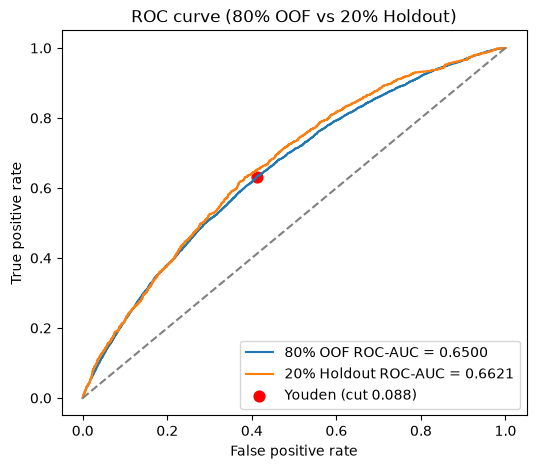

In [7]:
fpr, tpr, thresholds = roc_curve(y_train80, oof_final)
best      = np.argmax(tpr - fpr)
threshold = thresholds[best]

print(f"OOF AUC (80% train, prob) : {roc_auc_score(y_train80, oof_final):.4f}")
print(f"OOF AUC (80% train, label): {0.5 + (tpr[best] - fpr[best]) / 2:.4f}")
print(f"Holdout AUC (20%)          : {roc_auc_score(y_holdout20, holdout_final):.4f}")
print(f"Threshold (Youden)         : {threshold:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"80% OOF ROC-AUC = {roc_auc_score(y_train80, oof_final):.4f}")
fpr_h, tpr_h, _ = roc_curve(y_holdout20, holdout_final)
plt.plot(fpr_h, tpr_h, label=f"20% Holdout ROC-AUC = {roc_auc_score(y_holdout20, holdout_final):.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.scatter(fpr[best], tpr[best], s=60, color="red", label=f"Youden (cut {threshold:.3f})")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (80% OOF vs 20% Holdout)")
plt.legend(loc="lower right")
plt.show()


## 7. Submit


In [8]:
def make_submission(values, path):
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: values})
    sub = template[["ID"]].merge(sub, on="ID", how="left")
    sub.to_csv(path, index=False)
    return sub


proba_file = f"submission_proba_{RUN_NAME}.csv"
label_file = f"submission_label_{RUN_NAME}.csv"
sub_proba  = make_submission(pred_final, proba_file)
sub_label  = make_submission((pred_final >= threshold).astype(int), label_file)

print("✅ บันทึกไฟล์เสร็จสิ้น (โมเดล 80% Train / Holdout 20%)")
print(f"Probability File: {proba_file}")
print(f"Label (0/1) File: {label_file}")


✅ บันทึกไฟล์เสร็จสิ้น (โมเดล 80% Train / Holdout 20%)
Probability File: submission_proba_holdout80_ensemble.csv
Label (0/1) File: submission_label_holdout80_ensemble.csv


## 8. Final Analysis: 80/20 Holdout, Youden's J & Submission

ส่วนนี้ใช้แนวทาง **Train 80% / Holdout 20%** อย่างชัดเจน

1. แบ่งข้อมูล Train ทั้งหมดออกเป็น 80% สำหรับ Train และ 20% สำหรับ Holdout
   ด้วย `train_test_split(..., test_size=0.20, stratify=y, random_state=SEED)`
2. รัน Cross-Validation เฉพาะบน 80% Train และใช้ OOF ของ 80% ในการหา
   **Optimal Threshold** ด้วย **Youden's J statistic**
3. สร้าง **Confusion Matrix หลักบน 20% Holdout** (ประมาณ 13,710 แถว)
   ซึ่งเป็นข้อมูลที่ไม่ได้ถูกใช้ Train หรือเลือก Threshold
4. แสดง Confusion Matrix ของ 80% Train OOF เพิ่มเติมเพื่อใช้อ้างอิง
5. สร้างไฟล์ **Submission** จากโมเดลที่ Train บน 80% โดยใช้ Threshold เดียวกัน
   ทั้งแบบ probability และ label (0/1)
6. สรุปผลเชิงพฤติกรรมและข้อดี/ข้อเสียต่อธุรกิจจากผลบน Holdout จริง


1) OPTIMAL THRESHOLD (Youden's J) - 80% TRAIN OOF
Train 80% rows                 : 54,836 | Default rate: 9.6761%
Holdout 20% rows               : 13,710 | Default rate: 9.6791%
OOF ROC-AUC (80% train)        : 0.65003
OOF PR-AUC (80% train)         : 0.16212 | lift vs prevalence: 1.68x
OOF Brier score (80% train)    : 0.08541 | skill vs base: 0.0227
Holdout ROC-AUC (20%)          : 0.66212
Holdout PR-AUC (20%)           : 0.16806 | lift vs prevalence: 1.74x
Holdout Brier score (20%)      : 0.08517 | skill vs base: 0.0258
Best Youden's J (80% OOF)      : 0.22020
Optimal threshold              : 0.088129
TPR at threshold (80% OOF)     : 0.63249
FPR at threshold (80% OOF)     : 0.41230
Specificity at threshold       : 0.58770
Mean OOF probability (80%)     : 0.09683
Mean holdout probability (20%) : 0.09769


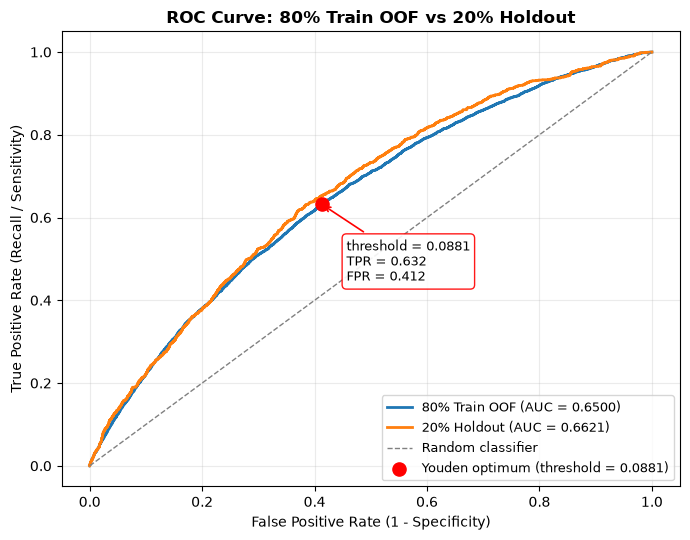

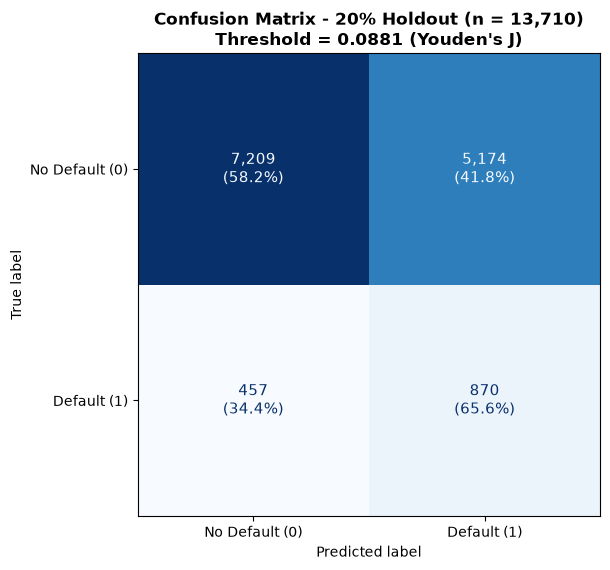

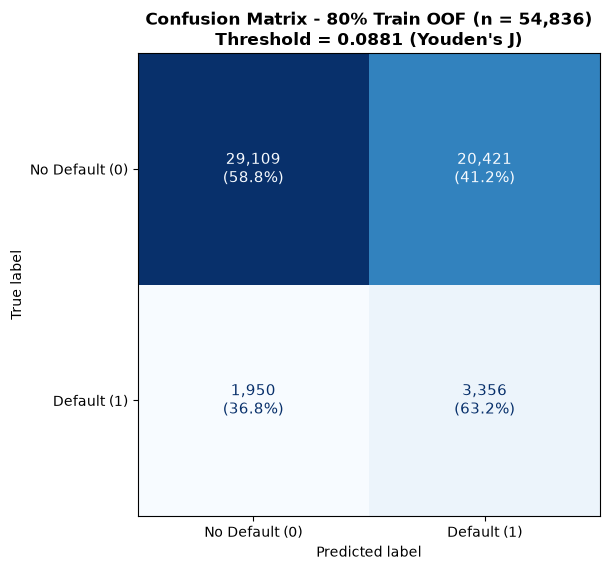


2) CONFUSION MATRIX & METRICS
                                 80% Train OOF       20% Holdout
N                                       54,836            13,710
Default                                  5,306             1,327
NonDefault                              49,530            12,383
TP                                       3,356               870
FN                                       1,950               457
FP                                      20,421             5,174
TN                                      29,109             7,209
Flagged                                 23,777             6,044

20% Holdout confusion matrix:
                                  Pred 0      Pred 1       Total
Actual 0 (No Default)              7,209       5,174      12,383
Actual 1 (Default)                   457         870       1,327
Total                              7,666       6,044      13,710

Recall            : OOF     0.6325 | Holdout     0.6556
Precision         : OOF     0.1411 |


3) SUBMISSION FILES (models trained on 80%)
Threshold ที่ใช้                   : 0.088129
Test rows                          : 137,091
Predicted Default (label = 1)      : 59,956 (43.73%)
Mean predicted probability (test)  : 0.096853
Min / Max probability (test)       : 0.044758 / 0.830979
Probability file                   : submission_proba_holdout80_ensemble_youden.csv
Label file                         : submission_label_holdout80_ensemble_youden.csv

4) BEHAVIORAL / BUSINESS SUMMARY - 20% HOLDOUT
20% Holdout: 13,710 ราย | Default จริง 1,327 ราย (9.68%) | ไม่ Default 12,383 ราย
โมเดลเตือน (pred = 1): 6,044 ราย (44.08% ของ Holdout)

- จับ Default ได้ (TP)                 : 870 / 1,327 = Recall 65.56%
- พลาด Default (FN)                   : 457 ราย = Miss rate 34.44%
- เตือนผิดว่าเป็น Default (FP)        : 5,174 ราย
- ไม่เตือนและถูก (TN)                 : 7,209 ราย
- ในกลุ่มที่โมเดลเตือน เป็น Default จริง (Precision) : 14.39%
- False Positive คิดเป็น               : 41.78% ของคนไม่ 

In [9]:
# =========================================================
# 8. FINAL ANALYSIS: 80/20 HOLDOUT
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
)

try:
    from IPython.display import display
except ImportError:
    display = print

# =========================================================
# 8.1 หา Threshold ด้วย Youden's J จาก OOF ของ 80% Train
# =========================================================
fpr_final, tpr_final, thresholds_final = roc_curve(y_train80, oof_final)
youden_j = tpr_final - fpr_final

best_idx = int(np.argmax(youden_j))
tied_idx = np.flatnonzero(np.isclose(youden_j, youden_j[best_idx]))
if len(tied_idx) > 1:
    best_idx = int(tied_idx[len(tied_idx) // 2])

best_threshold = float(thresholds_final[best_idx])
if not np.isfinite(best_threshold):
    best_threshold = 1.0

auc_oof = roc_auc_score(y_train80, oof_final)
ap_oof = average_precision_score(y_train80, oof_final)
brier_oof = brier_score_loss(y_train80, oof_final)
prevalence_oof = float(np.mean(y_train80))
brier_base_oof = prevalence_oof * (1 - prevalence_oof)
brier_skill_oof = 1 - brier_oof / brier_base_oof if brier_base_oof > 0 else np.nan
pr_lift_oof = ap_oof / prevalence_oof if prevalence_oof > 0 else np.inf

auc_hold = roc_auc_score(y_holdout20, holdout_final)
ap_hold = average_precision_score(y_holdout20, holdout_final)
brier_hold = brier_score_loss(y_holdout20, holdout_final)
prevalence_hold = float(np.mean(y_holdout20))
brier_base_hold = prevalence_hold * (1 - prevalence_hold)
brier_skill_hold = 1 - brier_hold / brier_base_hold if brier_base_hold > 0 else np.nan
pr_lift_hold = ap_hold / prevalence_hold if prevalence_hold > 0 else np.inf

print("=" * 82)
print("1) OPTIMAL THRESHOLD (Youden's J) - 80% TRAIN OOF")
print("=" * 82)
print(f"Train 80% rows                 : {len(y_train80):,} | Default rate: {prevalence_oof:.4%}")
print(f"Holdout 20% rows               : {len(y_holdout20):,} | Default rate: {prevalence_hold:.4%}")
print(f"OOF ROC-AUC (80% train)        : {auc_oof:.5f}")
print(f"OOF PR-AUC (80% train)         : {ap_oof:.5f} | lift vs prevalence: {pr_lift_oof:.2f}x")
print(f"OOF Brier score (80% train)    : {brier_oof:.5f} | skill vs base: {brier_skill_oof:.4f}")
print(f"Holdout ROC-AUC (20%)          : {auc_hold:.5f}")
print(f"Holdout PR-AUC (20%)           : {ap_hold:.5f} | lift vs prevalence: {pr_lift_hold:.2f}x")
print(f"Holdout Brier score (20%)      : {brier_hold:.5f} | skill vs base: {brier_skill_hold:.4f}")
print(f"Best Youden's J (80% OOF)      : {youden_j[best_idx]:.5f}")
print(f"Optimal threshold              : {best_threshold:.6f}")
print(f"TPR at threshold (80% OOF)     : {tpr_final[best_idx]:.5f}")
print(f"FPR at threshold (80% OOF)     : {fpr_final[best_idx]:.5f}")
print(f"Specificity at threshold       : {1 - fpr_final[best_idx]:.5f}")
print(f"Mean OOF probability (80%)     : {oof_final.mean():.5f}")
print(f"Mean holdout probability (20%) : {holdout_final.mean():.5f}")

# วาด ROC Curve ของ 80% OOF และ 20% Holdout
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr_final, tpr_final, lw=2, label=f"80% Train OOF (AUC = {auc_oof:.4f})")
fpr_h, tpr_h, _ = roc_curve(y_holdout20, holdout_final)
ax.plot(fpr_h, tpr_h, lw=2, label=f"20% Holdout (AUC = {auc_hold:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="Random classifier")
ax.scatter(
    fpr_final[best_idx],
    tpr_final[best_idx],
    s=90,
    color="red",
    zorder=5,
    label=f"Youden optimum (threshold = {best_threshold:.4f})",
)
ax.annotate(
    f"threshold = {best_threshold:.4f}\nTPR = {tpr_final[best_idx]:.3f}\nFPR = {fpr_final[best_idx]:.3f}",
    xy=(fpr_final[best_idx], tpr_final[best_idx]),
    xytext=(18, -55),
    textcoords="offset points",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="red", alpha=0.9),
    arrowprops=dict(arrowstyle="->", color="red", lw=1.2),
)
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax.set_title("ROC Curve: 80% Train OOF vs 20% Holdout", fontsize=12, fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# =========================================================
# 8.2 Confusion Matrix หลัก = 20% Holdout
# =========================================================
y_pred_holdout = (holdout_final >= best_threshold).astype(int)
cm_holdout = confusion_matrix(y_holdout20, y_pred_holdout, labels=[0, 1])

y_pred_train80 = (oof_final >= best_threshold).astype(int)
cm_train80 = confusion_matrix(y_train80, y_pred_train80, labels=[0, 1])


def plot_confusion(cm, title, ax):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Default (0)", "Default (1)"],
    )
    disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            text_idx = i * cm.shape[1] + j
            if text_idx < len(ax.texts):
                count = cm[i, j]
                row_total = cm[i].sum()
                row_pct = (count / row_total * 100) if row_total else 0.0
                ax.texts[text_idx].set_text(f"{count:,}\n({row_pct:.1f}%)")
                ax.texts[text_idx].set_fontsize(11)
    ax.set_title(title, fontsize=12, fontweight="bold")


fig, ax = plt.subplots(figsize=(6.8, 5.8))
plot_confusion(
    cm_holdout,
    f"Confusion Matrix - 20% Holdout (n = {len(y_holdout20):,})\n"
    f"Threshold = {best_threshold:.4f} (Youden's J)",
    ax,
)
plt.tight_layout()
plt.show()

# ตาราง CM ของ 80% Train OOF เพื่อใช้อ้างอิง (ไม่ใช่ตัวหลัก)
fig, ax = plt.subplots(figsize=(6.8, 5.8))
plot_confusion(
    cm_train80,
    f"Confusion Matrix - 80% Train OOF (n = {len(y_train80):,})\n"
    f"Threshold = {best_threshold:.4f} (Youden's J)",
    ax,
)
plt.tight_layout()
plt.show()

# =========================================================
# 8.3 Metrics: 20% Holdout (หลัก) และ 80% Train OOF (อ้างอิง)
# =========================================================
def binary_metrics(y_true, y_pred):
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_total_ = int(len(y_true))
    n_pos_ = int((np.asarray(y_true) == 1).sum())
    n_neg_ = int((np.asarray(y_true) == 0).sum())
    flagged_ = int(np.asarray(y_pred).sum())

    recall_ = tp_ / (tp_ + fn_) if (tp_ + fn_) > 0 else 0.0
    precision_ = tp_ / (tp_ + fp_) if (tp_ + fp_) > 0 else 0.0
    specificity_ = tn_ / (tn_ + fp_) if (tn_ + fp_) > 0 else 0.0
    fpr_ = fp_ / (fp_ + tn_) if (fp_ + tn_) > 0 else 0.0
    fnr_ = fn_ / (fn_ + tp_) if (fn_ + tp_) > 0 else 0.0
    npv_ = tn_ / (tn_ + fn_) if (tn_ + fn_) > 0 else 0.0

    return {
        "N": n_total_,
        "Default": n_pos_,
        "NonDefault": n_neg_,
        "TP": int(tp_),
        "FN": int(fn_),
        "FP": int(fp_),
        "TN": int(tn_),
        "Flagged": flagged_,
        "Flag_Rate": flagged_ / n_total_ if n_total_ else 0.0,
        "Recall": recall_,
        "Precision": precision_,
        "Specificity": specificity_,
        "FPR": fpr_,
        "FNR": fnr_,
        "NPV": npv_,
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Alerts_per_TP": (tp_ + fp_) / tp_ if tp_ > 0 else np.inf,
        "FP_per_TP": fp_ / tp_ if tp_ > 0 else np.inf,
    }


train_metrics = binary_metrics(y_train80, y_pred_train80)
hold_metrics = binary_metrics(y_holdout20, y_pred_holdout)
metrics_table = pd.DataFrame(
    [train_metrics, hold_metrics],
    index=["80% Train OOF", "20% Holdout"],
)

print()
print("=" * 82)
print("2) CONFUSION MATRIX & METRICS")
print("=" * 82)
print(f"{'':<28}{'80% Train OOF':>18}{'20% Holdout':>18}")
for key in ["N", "Default", "NonDefault", "TP", "FN", "FP", "TN", "Flagged"]:
    print(f"{key:<28}{train_metrics[key]:>18,}{hold_metrics[key]:>18,}")
print()

print("20% Holdout confusion matrix:")
print(f"{'':<28}{'Pred 0':>12}{'Pred 1':>12}{'Total':>12}")
print(f"{'Actual 0 (No Default)':<28}{hold_metrics['TN']:>12,}{hold_metrics['FP']:>12,}{hold_metrics['TN'] + hold_metrics['FP']:>12,}")
print(f"{'Actual 1 (Default)':<28}{hold_metrics['FN']:>12,}{hold_metrics['TP']:>12,}{hold_metrics['FN'] + hold_metrics['TP']:>12,}")
print(f"{'Total':<28}{hold_metrics['TN'] + hold_metrics['FN']:>12,}{hold_metrics['FP'] + hold_metrics['TP']:>12,}{hold_metrics['N']:>12,}")
print()

for key in [
    "Recall", "Precision", "Specificity", "FPR", "FNR", "NPV",
    "Accuracy", "F1", "Balanced_Accuracy", "Flag_Rate",
    "Alerts_per_TP", "FP_per_TP",
]:
    print(f"{key:<18}: OOF {train_metrics[key]:>10.4f} | Holdout {hold_metrics[key]:>10.4f}")

print()
print("Metrics table:")
print(metrics_table.round(4).to_string())

# =========================================================
# 8.4 Threshold trade-off บน 20% Holdout
# =========================================================
compare_thresholds = sorted(set([
    0.05,
    0.075,
    best_threshold,
    0.10,
    0.15,
    0.20,
    0.30,
    0.50,
]))
comparison_rows = []
for thr in compare_thresholds:
    pred_thr = (holdout_final >= thr).astype(int)
    m = binary_metrics(y_holdout20, pred_thr)
    comparison_rows.append({
        "threshold": thr,
        "flag_rate": m["Flag_Rate"],
        "recall": m["Recall"],
        "precision": m["Precision"],
        "specificity": m["Specificity"],
        "F1": m["F1"],
        "FP": m["FP"],
        "FN": m["FN"],
    })

comparison_df = pd.DataFrame(comparison_rows)
print()
print("Threshold trade-off (20% Holdout):")
print(comparison_df.round(4).to_string(index=False))

# =========================================================
# 8.5 สร้างไฟล์ Submission สำหรับ Test Data (จากโมเดล 80%)
# =========================================================
SUBMIT_RUN_NAME = f"{RUN_NAME}_youden"
proba_file = f"submission_proba_{SUBMIT_RUN_NAME}.csv"
label_file = f"submission_label_{SUBMIT_RUN_NAME}.csv"


def make_submission_final(values, path):
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: values})
    sub = template[["ID"]].merge(sub, on="ID", how="left")
    sub.to_csv(path, index=False)
    return sub


assert len(pred_final) == len(test), "pred_final กับ test มีจำนวนแถวไม่ตรงกัน"
assert not np.isnan(pred_final).any(), "pred_final มีค่า NaN"

test_pred_class = (pred_final >= best_threshold).astype(int)
sub_proba = make_submission_final(pred_final, proba_file)
sub_label = make_submission_final(test_pred_class, label_file)

print()
print("=" * 82)
print("3) SUBMISSION FILES (models trained on 80%)")
print("=" * 82)
print(f"Threshold ที่ใช้                   : {best_threshold:.6f}")
print(f"Test rows                          : {len(sub_label):,}")
print(f"Predicted Default (label = 1)      : {int(test_pred_class.sum()):,} ({test_pred_class.mean():.2%})")
print(f"Mean predicted probability (test)  : {pred_final.mean():.6f}")
print(f"Min / Max probability (test)       : {pred_final.min():.6f} / {pred_final.max():.6f}")
print(f"Probability file                   : {proba_file}")
print(f"Label file                         : {label_file}")

assert len(sub_proba) == len(template), "จำนวนแถว submission ไม่ตรงกับ template"
assert sub_proba["ID"].is_unique and sub_label["ID"].is_unique
assert sub_proba[["ID", TARGET]].notna().all().all()
assert sub_label[TARGET].isin([0, 1]).all()

# =========================================================
# 8.6 สรุปผลเชิงพฤติกรรมจาก 20% Holdout
# =========================================================
implied_cost_ratio = (1 - best_threshold) / best_threshold if best_threshold > 0 else np.inf

print()
print("=" * 82)
print("4) BEHAVIORAL / BUSINESS SUMMARY - 20% HOLDOUT")
print("=" * 82)
print(
    f"20% Holdout: {hold_metrics['N']:,} ราย | "
    f"Default จริง {hold_metrics['Default']:,} ราย ({prevalence_hold:.2%}) | "
    f"ไม่ Default {hold_metrics['NonDefault']:,} ราย"
)
print(f"โมเดลเตือน (pred = 1): {hold_metrics['Flagged']:,} ราย ({hold_metrics['Flag_Rate']:.2%} ของ Holdout)")
print()
print(f"- จับ Default ได้ (TP)                 : {hold_metrics['TP']:,} / {hold_metrics['Default']:,} = Recall {hold_metrics['Recall']:.2%}")
print(f"- พลาด Default (FN)                   : {hold_metrics['FN']:,} ราย = Miss rate {hold_metrics['FNR']:.2%}")
print(f"- เตือนผิดว่าเป็น Default (FP)        : {hold_metrics['FP']:,} ราย")
print(f"- ไม่เตือนและถูก (TN)                 : {hold_metrics['TN']:,} ราย")
print(f"- ในกลุ่มที่โมเดลเตือน เป็น Default จริง (Precision) : {hold_metrics['Precision']:.2%}")
print(f"- False Positive คิดเป็น               : {hold_metrics['FP'] / hold_metrics['NonDefault']:.2%} ของคนไม่ Default ทั้งหมด")
print(f"- False Positive คิดเป็น               : {hold_metrics['FP'] / hold_metrics['Flagged']:.2%} ของจำนวนที่เตือนทั้งหมด")
print(f"- ต้องเตือนประมาณ {hold_metrics['Alerts_per_TP']:.2f} ครั้ง เพื่อจับ Default ได้ 1 ราย")
print(f"- Accuracy {hold_metrics['Accuracy']:.2%} เทียบ baseline all-negative {1 - prevalence_hold:.2%}")
print(f"- PR-AUC {ap_hold:.4f} เทียบ baseline prevalence {prevalence_hold:.4f} = {pr_lift_hold:.2f}x")
print(f"- Brier skill เทียบ constant baseline = {brier_skill_hold:.4f}")
print()
print("เทียบ 80% Train OOF กับ 20% Holdout:")
print(f"- Recall    : OOF {train_metrics['Recall']:.2%} | Holdout {hold_metrics['Recall']:.2%} (Δ {hold_metrics['Recall'] - train_metrics['Recall']:+.2%})")
print(f"- Precision : OOF {train_metrics['Precision']:.2%} | Holdout {hold_metrics['Precision']:.2%} (Δ {hold_metrics['Precision'] - train_metrics['Precision']:+.2%})")
print(f"- Flag rate : OOF {train_metrics['Flag_Rate']:.2%} | Holdout {hold_metrics['Flag_Rate']:.2%} (Δ {hold_metrics['Flag_Rate'] - train_metrics['Flag_Rate']:+.2%})")
print(f"- F1        : OOF {train_metrics['F1']:.4f} | Holdout {hold_metrics['F1']:.4f}")
print()
print("ข้อควรระวังทางธุรกิจ:")
print("- Youden's J maximize TPR - FPR จึงให้น้ำหนัก Recall/Sensitivity กับ Specificity")
print("  ใกล้เคียงกัน แต่ไม่ได้แปลว่า profit สูงสุด เพราะต้นทุน FN กับ FP ไม่เท่ากัน")
print(f"- ถ้า probability มี calibration ดี threshold {best_threshold:.4f} จะ implicitly สอดคล้องกับ")
print(f"  ต้นทุน FN:FP ประมาณ {implied_cost_ratio:.1f}:1 (FN แพงกว่า FP ประมาณ {implied_cost_ratio:.1f} เท่า)")
print("  แต่ถ้า probability ไม่ calibrated ควรใช้ threshold นี้เป็น ranking cutoff มากกว่า")
print("  การตีความเป็น probability ของการ default จริง")
print("- ที่ Default Rate ต่ำ (~9.67%) precision จะถูกจำกัดด้วย base rate;")
print("  ควรดู Recall, PR-AUC, จำนวน FP และต้นทุนต่อธุรกิจร่วมกัน ไม่ควรดู Accuracy อย่างเดียว")
print("- Holdout 20% ไม่ถูกใช้ train หรือเลือก threshold จึงเป็นตัวเลขที่ใช้ประเมิน")
print("  Generalization ได้น่าเชื่อถือกว่า OOF; แต่ยังควรยืนยันด้วย Nested CV หรือ holdout อีกชุด")


### สรุปผลเชิงพฤติกรรมจากผลรันจริง (80% Train / 20% Holdout)

> ตัวเลขทั้งหมดด้านล่างมาจากการรัน Notebook นี้จริง โดยแบ่ง Train เป็น
> **80% Train = 54,836 แถว** และ **20% Holdout = 13,710 แถว**
> ใช้ OOF ของ 80% Train ในการเลือก Threshold และวัด Confusion Matrix หลักบน 20% Holdout
> ที่ไม่ถูกใช้ Train หรือเลือก Threshold

#### 1) ภาพรวมของ Threshold และผลการแยกกลุ่ม

| รายการ | 80% Train OOF | 20% Holdout |
|---|---:|---:|
| จำนวนแถว | 54,836 | 13,710 |
| จำนวน Default จริง | 5,306 (9.68%) | 1,327 (9.68%) |
| ROC-AUC | 0.65003 | 0.66212 |
| PR-AUC | 0.16212 | 0.16806 |
| PR-AUC เทียบ baseline prevalence | 1.68 เท่า | 1.74 เท่า |
| Brier Score | 0.08541 | 0.08517 |
| Brier Skill เทียบ constant baseline | 0.0227 | 0.0258 |
| Recall (ที่ Threshold นี้) | 63.25% | 65.56% |
| Precision (ที่ Threshold นี้) | 14.11% | 14.39% |
| Flag Rate | 43.36% | 44.08% |

- Youden's J สูงสุดบน OOF ของ 80% Train = **0.22020**
- Optimal Threshold = **0.088129**
- ที่ Threshold นี้ บน 80% OOF: TPR = 63.25%, FPR = 41.23%, Specificity = 58.77%
- Holdout AUC (0.66212) สูงกว่า OOF AUC (0.65003) เล็กน้อย และ Recall/Precision บน Holdout
  ใกล้เคียงกับ OOF มาก แสดงว่าโมเดลไม่ได้ overfit อย่างรุนแรง แต่ความสามารถในการแยกกลุ่ม
  โดยรวมยังอยู่ในระดับปานกลาง

#### 2) Confusion Matrix หลัก: 20% Holdout (13,710 แถว)

|  | Pred 0 (ไม่เตือน) | Pred 1 (เตือน) | Total |
|---|---:|---:|---:|
| **Actual 0 (ไม่ Default)** | TN = 7,209 | FP = 5,174 | 12,383 |
| **Actual 1 (Default)** | FN = 457 | TP = 870 | 1,327 |
| **Total** | 7,666 | 6,044 | 13,710 |

โมเดลเตือนทั้งหมด **6,044 ราย คิดเป็น 44.08% ของ Holdout**
ซึ่งสูงกว่า Default Rate จริง (9.68%) มาก เช่นเดียวกับพฤติกรรมบน OOF

| Metric | 80% OOF | 20% Holdout | ความหมาย |
|---|---:|---:|---|
| Recall / Sensitivity | 63.25% | **65.56%** | จับ Default ได้ 870 จาก 1,327 ราย |
| Miss Rate / FNR | 36.75% | **34.44%** | พลาด Default 457 ราย |
| Precision (PPV) | 14.11% | **14.39%** | ในกลุ่มที่เตือน เป็น Default จริงประมาณ 1 ใน 7 |
| Specificity (TNR) | 58.77% | **58.22%** | ไม่ Default และไม่ถูกเตือน 7,209 จาก 12,383 ราย |
| False Positive Rate | 41.23% | **41.78%** | คนไม่ Default ถูกเตือนผิด 41.78% |
| Negative Predictive Value | 93.72% | **94.04%** | ในกลุ่มที่ไม่เตือน ส่วนใหญ่ไม่ Default จริง |
| Accuracy | 59.20% | **58.93%** | ต่ำกว่า baseline all-negative (90.32%) มาก |
| F1-score | 0.2308 | **0.2361** | สมดุล Recall/Precision ยังต่ำ |
| Balanced Accuracy | 61.01% | **61.89%** | ค่าเฉลี่ย Recall กับ Specificity |
| Flag Rate | 43.36% | **44.08%** | เตือน 6,044 จาก 13,710 ราย |

#### 3) จับกลุ่มคนผิดนัดชำระหนี้ (Default) ได้แม่นยำแค่ไหน

- **True Positive (TP) = 870 ราย** จาก Default ทั้งหมด 1,327 ราย
- **Recall = 65.56%** หมายความว่าโมเดลจับ Default ได้ประมาณ 2 ใน 3
- **False Negative (FN) = 457 ราย** หรือพลาดไป 34.44% ของ Default ทั้งหมด
- หากสุ่มเตือน 44.08% ของประชากร จะจับ Default ได้ประมาณ 44.08% แต่โมเดลจับได้ 65.56%
  คิดเป็น lift ด้าน Recall ประมาณ 1.49 เท่า
- Precision 14.39% เทียบ baseline Default Rate 9.68% คิดเป็น lift ประมาณ 1.49 เท่า
- PR-AUC 0.16806 เทียบ baseline 0.09679 คิดเป็น lift ประมาณ 1.74 เท่า
- สรุปคือโมเดลมีสัญญาณจริงและ-generalize ได้พอสมควร แต่ยังแยกกลุ่ม Default กับไม่ Default
  ได้ไม่คมชัด (ROC-AUC ประมาณ 0.66)

#### 4) False Positive (เตือนผิดว่าเป็นหนี้เสีย) มากแค่ไหน

- **False Positive (FP) = 5,174 ราย**
- คิดเป็น **41.78% ของคนที่ไม่ Default ทั้งหมด** (5,174 / 12,383)
- คิดเป็น **85.61% ของจำนวนที่โมเดลเตือนทั้งหมด** (5,174 / 6,044)
- เทียบอัตราส่วน: มี **FP ประมาณ 5.95 ราย ต่อ TP 1 ราย**
- ต้องเตือนประมาณ **6.95 ครั้ง เพื่อจับ Default ได้ 1 ราย**

ผลกระทบเชิงปฏิบัติ: หากทีม Review ตรวจสอบ 100 ราย
ในจำนวนนี้จะเป็น Default จริงเพียงประมาณ 14 ราย และเป็น False Positive ประมาณ 86 ราย
ทำให้ต้นทุนการตรวจสอบต่อการจับ Default 1 รายสูง และอาจสร้างความไม่พอใจ
หรือทำให้ลูกค้าที่ดีถูกปฏิเสธ/ถูกจำกัดวงเงินโดยไม่จำเป็น

#### 5) ความหมายต่อธุรกิจ เมื่อ Default Rate ประมาณ 9.67%

**ข้อดีของ Threshold นี้**

- จับ Default ได้ถึง **65.56%** (870 ราย) และผลบน Holdout ใกล้เคียง OOF
  (Recall ต่างกันเพียง +2.31 percentage points) แสดงว่า Threshold ที่เลือกจาก 80% OOF
  ใช้งานกับข้อมูลใหม่ได้ reasonably well
- เหมาะกับสถานการณ์ที่ **ต้นทุนของการพลาด Default (FN) สูงกว่าต้นทุนการเตือนผิด (FP) มาก**
  เช่น ต้องการคัดกรองเพื่อส่งทีมติดตามหรือสอบทานเพิ่มเติม
- เป็นวิธีที่อธิบายได้ง่าย ไม่ต้องกำหนดต้นทุนทางธุรกิจล่วงหน้า และคำนวณจาก ROC Curve โดยตรง
- หากธุรกิจมีกำลังคนเพียงพอที่จะตรวจสอบลูกค้าประมาณ 44% ของพอร์ต
  Threshold นี้ใช้เป็น "ตะแกรงหยาบ" เพื่อคัดกลุ่มเสี่ยงเข้ากระบวนการ Review ได้

**ข้อเสียและความเสี่ยง**

- **Flag rate สูงถึง 44.08% ของ Holdout (และ 43.73% ของ Test)**
  ทำให้ภาระการตรวจสอบและต้นทุนดำเนินการสูงมาก
- **Precision เพียง 14.39%** แปลว่า 85.61% ของการเตือนเป็น False Positive
  ไม่เหมาะกับการนำไปใช้ "ปฏิเสธสินเชื่ออัตโนมัติ" โดยตรง
- **Accuracy 58.93% ต่ำกว่า baseline all-negative 90.32%** เพราะโมเดลยอม flag คนจำนวนมาก
  Accuracy จึงเป็นตัวชี้วัดที่ทำให้เข้าใจผิดในข้อมูล imbalance แบบนี้
- **Youden's J ไม่ได้ optimize กำไรหรือต้นทุนธุรกิจ** แต่ให้น้ำหนัก Recall และ Specificity
  ใกล้เคียงกัน โดยไม่สนใจว่าต้นทุน FN กับ FP จริง ๆ ต่างกันแค่ไหน
- ค่า Brier Skill เทียบ constant baseline มีเพียง **0.0258** (ดีขึ้นประมาณ 2.6%)
  และ PR-AUC lift 1.74 เท่า สะท้อนว่า **ความสามารถในการแยกกลุ่มยังจำกัด**
  จึงไม่ควรคาดหวัง Precision สูงที่ Recall 65%
- Threshold 0.088 อยู่บริเวณที่คะแนนของลูกค้าจำนวนมากเกาะกลุ่มกัน
  การขยับ Threshold เล็กน้อยจึงเปลี่ยนจำนวนคนที่ถูก flag มาก (ดูตารางด้านล่าง)
- แม้ Holdout จะไม่ได้ถูกใช้ Train หรือเลือก Threshold แต่ Frequency Encoding ใน Cell 5
  ยังคำนวณจาก Train+Test ทั้งหมด หากต้องการ Holdout ที่เข้มงวดที่สุด
  ควร fit frequency map จาก 80% Train เท่านั้น

**ทางเลือกเชิงต้นทุน (Cost-sensitive view)**

ภายใต้สมมติฐานว่า probability มี calibration ดี การเลือก Threshold ที่ลดต้นทุนรวม
สามารถใช้สูตร `Threshold ≈ C_FP / (C_FP + C_FN)` เมื่อ `C_FP` คือต้นทุนต่อ False Positive
และ `C_FN` คือต้นทุนต่อ False Negative

- Threshold 0.088 สอดคล้องกับอัตราต้นทุน **FN : FP ประมาณ 10.3 : 1**
  (ถ้า FN แพงกว่า FP ประมาณ 10.3 เท่า การ flag กว้างแบบนี้อาจสมเหตุสมผล)
- ถ้าต้นทุน FN : FP เป็น **5 : 1** สูตรจะให้ Threshold ประมาณ **0.167**
  ซึ่งจะลดจำนวนคนที่ถูก flag และเพิ่ม Precision แต่ Recall จะลดลง
- ถ้าต้นทุน FP สูง เช่น เสียลูกค้าดี เสียรายได้ หรือมีต้นทุนตรวจสอบสูง
  ควรขึ้น Threshold เป็นประมาณ **0.15-0.20** ซึ่งบน Holdout จะเหลือ Flag rate ประมาณ 10.3%-3.8%
  แต่ Recall จะเหลือเพียง 21.0%-9.8%
- ถ้าต้นทุน FN สูงมากและมีกำลังตรวจสอบเพียงพอ อาจพิจารณา Threshold ต่ำลง
  (เช่น 0.05-0.075) ซึ่งจะจับ Default ได้ 99.9%-82.1% แต่ต้องแลกกับ Flag rate 99.6%-62.8%

**ตาราง Trade-off ของ Threshold บน 20% Holdout**

| Threshold | Flag Rate | Recall | Precision | Specificity | FP | FN |
|---:|---:|---:|---:|---:|---:|---:|
| 0.050 | 99.61% | 99.92% | 9.71% | 0.43% | 12,330 | 1 |
| 0.075 | 62.76% | 82.06% | 12.66% | 39.30% | 7,516 | 238 |
| **0.088 (Youden)** | **44.08%** | **65.56%** | **14.39%** | **58.22%** | **5,174** | **457** |
| 0.100 | 32.32% | 52.52% | 15.73% | 69.85% | 3,734 | 630 |
| 0.150 | 10.30% | 21.02% | 19.76% | 90.85% | 1,133 | 1,048 |
| 0.200 | 3.81% | 9.80% | 24.86% | 96.83% | 393 | 1,197 |
| 0.300 | 0.88% | 2.34% | 25.62% | 99.27% | 90 | 1,296 |
| 0.500 | 0.07% | 0.30% | 44.44% | 99.96% | 5 | 1,323 |

จะเห็นว่าไม่มีจุดใดที่ได้ทั้ง Recall และ Precision สูงพร้อมกัน เพราะโมเดลมี
ROC-AUC ประมาณ 0.66 และ PR-AUC ประมาณ 0.168 ซึ่งเป็นข้อจำกัดของตัวโมเดลเอง
การเลือก Threshold จึงเป็นการเลือก "จุดสมดุลทางธุรกิจ" มากกว่าการหาค่าที่ดีที่สุดเพียงค่าเดียว

#### 6) ข้อเสนอแนะเชิงปฏิบัติ

1. **ใช้ Confusion Matrix บน 20% Holdout เป็นตัวเลขหลักในการรายงาน** เพราะไม่ถูกใช้
   Train หรือเลือก Threshold และให้ภาพ Generalization ที่น่าเชื่อถือกว่า OOF
2. **อย่าใช้ Threshold 0.088 เพื่ออนุมัติ/ปฏิเสธอัตโนมัติ** เพราะ False Positive สูงถึง 85.61%
   ควรใช้เป็นเกณฑ์คัดกรองเพื่อส่งเข้าคิว Review หรือใช้ร่วมกับกฎธุรกิจอื่น
3. **กำหนด Threshold จากกำลังคนและต้นทุนจริง** เช่น ถ้าตรวจได้เพียง 10% ของพอร์ต
   ให้ใช้ Threshold ประมาณ 0.15 (Recall 21.0%, Precision 19.8%) หรือใช้วิธี Top-K Ranking
   แทนการ fix ค่า probability ก็ได้
4. **สร้าง Cost Matrix และเลือก Threshold ที่ลดต้นทุนรวม**
   `Total Cost = FN × C_FN + FP × C_FP` แล้วทดสอบหลายค่า Threshold บน Holdout
5. **Calibrate probability** (เช่น Isotonic หรือ Platt Scaling) ก่อนตีความค่า 0.088
   ว่าเป็น "โอกาส Default 8.8%" เพราะ Brier Skill ยังต่ำและ probability อาจไม่ calibrated
6. **ตรวจสอบซ้ำด้วย Nested CV หรือ Holdout อีกชุด** เพื่อลด Selection Bias
   จากการเลือก Threshold บน OOF ของ 80% Train
7. **พิจารณาพัฒนาโมเดลเพิ่ม** เพราะ ROC-AUC 0.662 และ PR-AUC 0.168 ยังเป็นข้อจำกัดหลัก
   การปรับ Threshold อย่างเดียวไม่สามารถแก้ปัญหา Precision ต่ำที่ Recall สูงได้
8. **การส่งประกวด**: ไฟล์ probability (`submission_proba_holdout80_ensemble_youden.csv`)
   ปลอดภัยกว่าถ้า Metric เป็น AUC เพราะเก็บ ranking ครบ ส่วนไฟล์ label
   (`submission_label_holdout80_ensemble_youden.csv`) ใช้ Youden Threshold
   และ flag 43.73% ของ Test ซึ่งอาจมากเกินไปหาก Metric ลงโทษ False Positive
   หรือกำหนดสัดส่วน Positive ที่เหมาะสม ควรเลือก Threshold ให้ตรงกับ Metric ของการแข่งขัน

#### 7) ไฟล์ที่สร้างจาก Notebook นี้

- `submission_proba_holdout80_ensemble.csv` - probability จากโมเดล 80% (Cell 15)
- `submission_label_holdout80_ensemble.csv` - label 0/1 จากโมเดล 80% (Cell 15)
- `submission_proba_holdout80_ensemble_youden.csv` - probability จาก Final Analysis (Cell 17)
- `submission_label_holdout80_ensemble_youden.csv` - label 0/1 จาก Final Analysis (Cell 17)
  (predicted default 59,956 ราย คิดเป็น 43.73% ของ Test)
- ไฟล์ submission จากเวอร์ชัน full-train เดิมยังคงอยู่แยกต่างหาก
